In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/retail_customers_clean.csv",
    parse_dates=["InvoiceDate"]
)

print(df.shape)
df.head()

(779495, 10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancellation,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


In [2]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_summary = (
    df.groupby("Customer ID")
    .agg(
        last_purchase=("InvoiceDate", "max"),
        frequency=("Invoice", "nunique"),
        monetary_value=("Revenue", "sum"),
    )
    .reset_index()
)

customer_summary["recency"] = (
    snapshot_date - customer_summary["last_purchase"]
).dt.days

customer_summary.head()

,Customer ID,last_purchase,frequency,monetary_value,recency
0,12346.0,2011-01-18 10:01:00,12,77556.46,326
1,12347.0,2011-12-07 15:52:00,8,4921.53,2
2,12348.0,2011-09-25 13:13:00,5,2019.40,75
3,12349.0,2011-11-21 09:51:00,4,4428.69,19
4,12350.0,2011-02-02 16:01:00,1,334.40,310


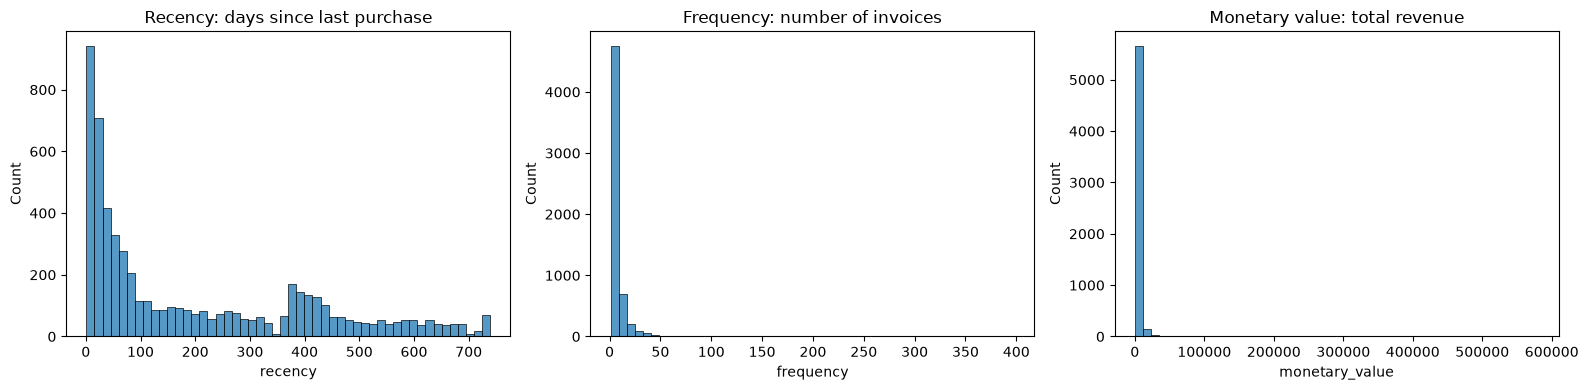

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(customer_summary["recency"], bins=50, ax=axes[0])
axes[0].set_title("Recency: days since last purchase")

sns.histplot(customer_summary["frequency"], bins=50, ax=axes[1])
axes[1].set_title("Frequency: number of invoices")

sns.histplot(customer_summary["monetary_value"], bins=50, ax=axes[2])
axes[2].set_title("Monetary value: total revenue")

plt.tight_layout()
plt.show()

In [4]:
print("Customer count:", len(customer_summary))
print("Zero-price rows:", df["Price"].eq(0).sum())
print("Negative-price rows:", df["Price"].lt(0).sum())

customer_summary[
    ["recency", "frequency", "monetary_value"]
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

Customer count: 5881
Zero-price rows: 70
Negative-price rows: 0


,recency,frequency,monetary_value
count,5881.000000,5881.000000,5881.000000
mean,201.457745,6.287196,2954.396237
std,209.474135,13.012879,14437.322635
min,1.000000,1.000000,0.000000
25%,26.000000,1.000000,341.900000
50%,96.000000,3.000000,865.600000
75%,380.000000,7.000000,2247.720000
90%,536.000000,13.000000,5464.850000
95%,626.000000,21.000000,9371.710000
99%,726.000000,46.000000,29181.400000


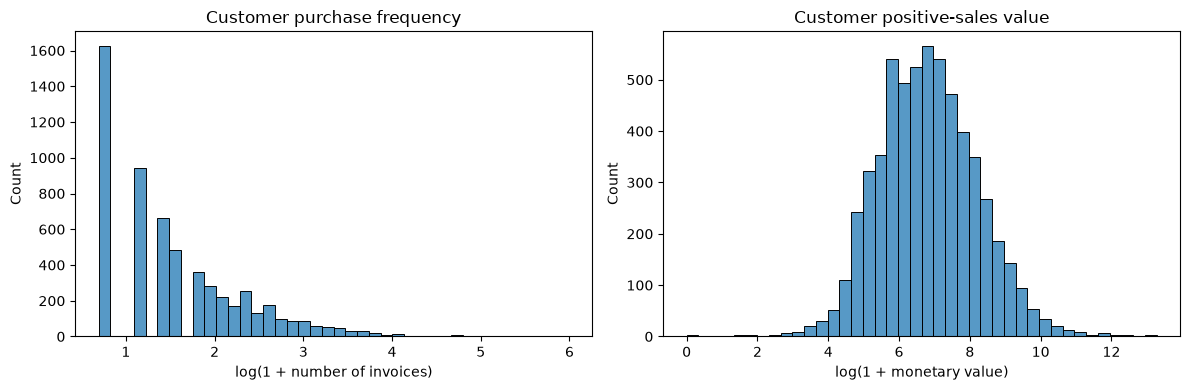

In [5]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    np.log1p(customer_summary["frequency"]),
    bins=40,
    ax=axes[0]
)
axes[0].set_title("Customer purchase frequency")
axes[0].set_xlabel("log(1 + number of invoices)")

sns.histplot(
    np.log1p(customer_summary["monetary_value"]),
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Customer positive-sales value")
axes[1].set_xlabel("log(1 + monetary value)")

plt.tight_layout()
plt.show()

In [6]:
# Keep the original cleaned data unchanged.
df_paid = df.loc[df["Price"] > 0].copy()

# Keep the reference date anchored to the full dataset.
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

customer_summary = (
    df_paid.groupby("Customer ID")
    .agg(
        last_purchase=("InvoiceDate", "max"),
        frequency=("Invoice", "nunique"),
        monetary_value=("Revenue", "sum"),
    )
    .reset_index()
)

customer_summary["recency"] = (
    snapshot_date - customer_summary["last_purchase"].dt.normalize()
).dt.days

print("Paid-sales rows:", len(df_paid))
print("Customers with paid purchases:", len(customer_summary))

customer_summary.head()

Paid-sales rows: 779425
Customers with paid purchases: 5878


,Customer ID,last_purchase,frequency,monetary_value,recency
0,12346.0,2011-01-18 10:01:00,12,77556.46,326
1,12347.0,2011-12-07 15:52:00,8,4921.53,3
2,12348.0,2011-09-25 13:13:00,5,2019.40,76
3,12349.0,2011-11-21 09:51:00,4,4428.69,19
4,12350.0,2011-02-02 16:01:00,1,334.40,311


In [7]:
customer_summary["R_score"] = pd.cut(
    customer_summary["recency"],
    bins=[-1, 26, 96, 380, float("inf")],
    labels=[4, 3, 2, 1]
).astype(int)

customer_summary["F_score"] = pd.cut(
    customer_summary["frequency"],
    bins=[0, 1, 3, 7, float("inf")],
    labels=[1, 2, 3, 4]
).astype(int)

customer_summary["M_score"] = pd.cut(
    customer_summary["monetary_value"],
    bins=[0, 341.90, 865.60, 2247.72, float("inf")],
    labels=[1, 2, 3, 4]
).astype(int)

customer_summary["RFM_code"] = (
    customer_summary[["R_score", "F_score", "M_score"]]
    .astype(str)
    .agg("".join, axis=1)
)

customer_summary.head()

,Customer ID,last_purchase,frequency,monetary_value,recency,R_score,F_score,M_score,RFM_code
0,12346.0,2011-01-18 10:01:00,12,77556.46,326,2,4,4,244
1,12347.0,2011-12-07 15:52:00,8,4921.53,3,4,4,4,444
2,12348.0,2011-09-25 13:13:00,5,2019.40,76,3,3,3,333
3,12349.0,2011-11-21 09:51:00,4,4428.69,19,4,3,4,434
4,12350.0,2011-02-02 16:01:00,1,334.40,311,2,1,1,211


In [8]:
print(
    customer_summary[["R_score", "F_score", "M_score"]]
    .apply(lambda column: column.value_counts())
    .sort_index()
)

customer_summary.to_csv(
    "../data/processed/customer_rfm.csv",
    index=False
)

print("Customer RFM table saved.")

   R_score  F_score  M_score
1     1467     1623     1468
2     1464     1608     1470
3     1460     1348     1470
4     1487     1299     1470
Customer RFM table saved.


In [9]:
import numpy as np

r = customer_summary["R_score"]
f = customer_summary["F_score"]
m = customer_summary["M_score"]

conditions = [
    (r == 4) & (f >= 3) & (m >= 3),
    (r >= 3) & (f >= 3),
    (r >= 3) & (f == 1),
    (r >= 3) & (f == 2),
    (r <= 2) & ((f >= 3) | (m >= 3)),
    (r == 2),
    (r == 1),
]

labels = [
    "Champions",
    "Loyal customers",
    "Recent one-time buyers",
    "Developing repeat buyers",
    "At-risk valuable customers",
    "Needs attention",
    "Long inactive",
]

customer_summary["segment"] = np.select(
    conditions,
    labels,
    default="Review"
)

customer_summary[[
    "Customer ID", "recency", "frequency",
    "monetary_value", "RFM_code", "segment"
]].head(10)

,Customer ID,recency,frequency,monetary_value,RFM_code,segment
0,12346.0,326,12,77556.46,244,At-risk valuable customers
1,12347.0,3,8,4921.53,444,Champions
2,12348.0,76,5,2019.40,333,Loyal customers
3,12349.0,19,4,4428.69,434,Champions
4,12350.0,311,1,334.40,211,Needs attention
5,12351.0,376,1,300.93,211,Needs attention
6,12352.0,37,10,2849.84,344,Loyal customers
7,12353.0,205,2,406.76,222,Needs attention
8,12354.0,233,1,1079.40,213,At-risk valuable customers
9,12355.0,215,2,947.61,223,At-risk valuable customers


In [10]:
segment_summary = (
    customer_summary.groupby("segment")
    .agg(
        customers=("Customer ID", "nunique"),
        median_recency_days=("recency", "median"),
        median_invoices=("frequency", "median"),
        median_sales_value=("monetary_value", "median"),
        total_sales_value=("monetary_value", "sum"),
    )
    .sort_values("customers", ascending=False)
)

segment_summary["customer_share_pct"] = (
    segment_summary["customers"] / len(customer_summary) * 100
)

assert segment_summary["customers"].sum() == len(customer_summary)
assert not customer_summary["segment"].eq("Review").any()

segment_summary.round(2)

,customers,median_recency_days,median_invoices,median_sales_value,total_sales_value,customer_share_pct
segment,,,,,,
Long inactive,1131,510.0,1.0,258.55,342221.29,19.24
At-risk valuable customers,1076,265.0,4.0,1409.57,2686114.03,18.31
Champions,1015,10.0,11.0,3760.29,10075725.82,17.27
Loyal customers,887,50.0,7.0,2262.05,3097016.46,15.09
Needs attention,724,244.0,1.0,328.58,264947.72,12.32
Developing repeat buyers,674,31.0,2.0,684.58,768491.74,11.47
Recent one-time buyers,371,46.0,1.0,267.13,140287.21,6.31


In [11]:
customer_summary.to_csv(
    "../data/processed/customer_rfm.csv",
    index=False
)

segment_summary.to_csv(
    "../data/processed/segment_summary.csv"
)

print("Saved customer segments and segment summary.")

Saved customer segments and segment summary.


In [12]:
segment_summary["sales_share_pct"] = (
    segment_summary["total_sales_value"]
    / segment_summary["total_sales_value"].sum()
    * 100
)

segment_summary[[
    "customers",
    "customer_share_pct",
    "total_sales_value",
    "sales_share_pct",
    "median_recency_days",
]].round(2)

,customers,customer_share_pct,total_sales_value,sales_share_pct,median_recency_days
segment,,,,,
Long inactive,1131,19.24,342221.29,1.97,510.0
At-risk valuable customers,1076,18.31,2686114.03,15.46,265.0
Champions,1015,17.27,10075725.82,57.99,10.0
Loyal customers,887,15.09,3097016.46,17.82,50.0
Needs attention,724,12.32,264947.72,1.52,244.0
Developing repeat buyers,674,11.47,768491.74,4.42,31.0
Recent one-time buyers,371,6.31,140287.21,0.81,46.0


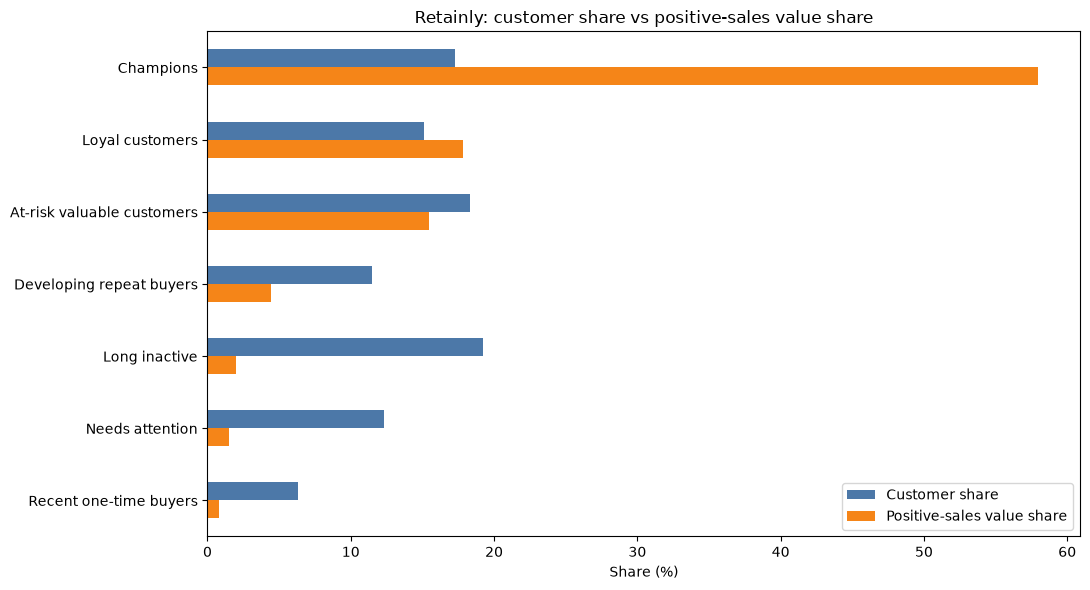

In [13]:
from pathlib import Path

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plot_data = (
    segment_summary[
        ["customer_share_pct", "sales_share_pct"]
    ]
    .sort_values("sales_share_pct", ascending=False)
    .rename(columns={
        "customer_share_pct": "Customer share",
        "sales_share_pct": "Positive-sales value share",
    })
)

ax = plot_data.plot.barh(
    figsize=(11, 6),
    color=["#4C78A8", "#F58518"]
)

ax.invert_yaxis()
ax.set_title("Retainly: customer share vs positive-sales value share")
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.legend(title="")

plt.tight_layout()
plt.savefig(
    figure_dir / "segment_customer_vs_sales_share.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [14]:
segment_summary.to_csv(
    "../data/processed/segment_summary.csv"
)

print("Updated summary and segment chart saved.")

Updated summary and segment chart saved.
